# Bank Loan Analysis

## Importing required libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import plotly.express as px

### Importing datset

In [2]:
df = pd.read_excel("C://Nazim Khan//Data Analytics//Projects//Project_Bank_Loan_Analysis//financial_loan.xlsx")

In [23]:
df.head(5)

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,2021-02-11,2021-09-13,2021-04-13,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,2021-01-01,2021-12-14,2021-01-15,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,2021-01-05,2021-12-12,2021-01-09,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,2021-02-25,2021-12-12,2021-03-12,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,2021-01-01,2021-12-14,2021-01-15,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


#### Metadata of Data

In [3]:
print(f"Number of rows: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

Number of rows :38576
Number of columns :24


### Datatypes

In [4]:
df.dtypes

id                                int64
address_state                       str
application_type                    str
emp_length                          str
emp_title                        object
grade                               str
home_ownership                      str
issue_date               datetime64[us]
last_credit_pull_date    datetime64[us]
last_payment_date        datetime64[us]
loan_status                         str
next_payment_date        datetime64[us]
member_id                         int64
purpose                             str
sub_grade                           str
term                                str
verification_status                 str
annual_income                   float64
dti                             float64
installment                     float64
int_rate                        float64
loan_amount                       int64
total_acc                         int64
total_payment                     int64
dtype: object

In [5]:
df.describe()

,id,issue_date,last_credit_pull_date,last_payment_date,next_payment_date,member_id,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
count,3.857600e+04,38576,38576,38576,38576,3.857600e+04,3.857600e+04,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000,38576.000000
mean,6.810371e+05,2021-07-16 02:31:35.562007,2021-06-08 13:36:34.193280,2021-06-26 09:52:08.909166,2021-07-26 20:42:20.605557,8.476515e+05,6.964454e+04,0.133274,326.862965,0.120488,11296.066855,22.132544,12263.348533
min,5.473400e+04,2021-01-01 00:00:00,2021-01-08 00:00:00,2021-01-08 00:00:00,2021-02-08 00:00:00,7.069900e+04,4.000000e+03,0.000000,15.690000,0.054200,500.000000,2.000000,34.000000
25%,5.135170e+05,2021-04-11 00:00:00,2021-04-15 00:00:00,2021-03-16 00:00:00,2021-04-16 00:00:00,6.629788e+05,4.150000e+04,0.082100,168.450000,0.093200,5500.000000,14.000000,5633.000000
50%,6.627280e+05,2021-07-11 00:00:00,2021-05-16 00:00:00,2021-06-14 00:00:00,2021-07-14 00:00:00,8.473565e+05,6.000000e+04,0.134200,283.045000,0.118600,10000.000000,20.000000,10042.000000
75%,8.365060e+05,2021-10-11 00:00:00,2021-08-13 00:00:00,2021-09-15 00:00:00,2021-10-15 00:00:00,1.045652e+06,8.320050e+04,0.185900,434.442500,0.145900,15000.000000,29.000000,16658.000000
max,1.077501e+06,2021-12-12 00:00:00,2022-01-20 00:00:00,2021-12-15 00:00:00,2022-01-15 00:00:00,1.314167e+06,6.000000e+06,0.299900,1305.190000,0.245900,35000.000000,90.000000,58564.000000
std,2.113246e+05,NaN,NaN,NaN,NaN,2.668105e+05,6.429368e+04,0.066662,209.092000,0.037164,7460.746022,11.392282,9051.104777


### Total Loan Applications

In [6]:
total_loan_applications = df['id'].count
print(f"Total Loan Applications: {total_loan_applications}")

Total Loan Applications : <bound method Series.count of 0        1077430
1        1072053
2        1069243
3        1041756
4        1068350
          ...   
38571     803452
38572     970377
38573     875376
38574     972997
38575     682952
Name: id, Length: 38576, dtype: int64>


### MTD Total Loan Applications

In [7]:
latest_issue_date = df['issue_date'].max()
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

mtd_data = df[(df['issue_date'].dt.year == latest_year) & (df['issue_date'].dt.month == latest_month)]

mtd_loan_applications = mtd_data['id'].count()

print(f"MTD Loan Applications: (for { latest_issue_date.strftime('%B %Y')}) :{mtd_loan_applications}")
print(df['issue_date'].max())

MTD Loan Applications : (for December 2021) :4314
2021-12-12 00:00:00


### Total Funded Amount

In [8]:
total_funded_amount = df['loan_amount'].sum()
total_funded_amount_in_millions = total_funded_amount/1000000
print(f" Total Funded Amount: ${total_funded_amount_in_millions:.2f}M ")

 Total Funded Amount : $435.76M 


### MTD - Total Funded Amount

In [9]:
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

mtd_data_funded = df[(df['issue_date'].dt.year == latest_year) & (df['issue_date'].dt.month == latest_month)]

mtd_total_funded_amount = mtd_data_funded['loan_amount'].sum()
mtd_total_funded_amount_in_millions = mtd_total_funded_amount/1000000

print(f"MTD Total Funded Amount: ${mtd_total_funded_amount_in_millions:.2f}M ")

MTD Total Funded Amount $53.98M 


### Total Amount Recieved

In [11]:
total_amount_received = df['total_payment'].sum()
total_amount_received_in_millions = total_amount_received/1000000

print(f"Total Funded Amount: ${total_amount_received_in_millions:.2f}M ")

Total Funded Amount $473.07M 


### MTD Total Amount Recieved

In [16]:
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

mtd_data_recevied = df[(df['issue_date'].dt.year == latest_year) & (df['issue_date'].dt.month == latest_month)]

mtd_total_amount_received = mtd_data_funded['total_payment'].sum()
mtd_total_amount_received_in_millions = mtd_total_funded_amount/1000000

print(f"MTD Total Funded Amount: ${mtd_total_amount_received_in_millions:.2f}M ")

MTD Total Funded Amount $53.98M 


### Average Interest Rate

In [18]:
average_interest_rate = df['int_rate'].mean()*100
print(f" Average Interest Rate: {average_interest_rate:.2f}% ")

 Average Interest Rate : 12.05% 


### Average Debt-to-Income Ratio (DTI)

In [19]:
average_dti =df['dti'].mean()*100
print(f"Average DTI Ratio: {average_dti:.2f}%")

Average DTI Ratio: 13.33%


### Good Loans Metrics

In [34]:
good_loans = df[df['loan_status'].isin(['Fully Paid','Current'])] # create good loans

total_good_loan_applications = df['id'].count()

good_loan_applications = good_loans['id'].count()
good_loan_funded_amount = good_loans['loan_amount'].sum()
good_loan_amount_received = good_loans['total_payment'].sum()

good_loan_funded_in_millions = good_loan_funded_amount/1000000
good_loan_amount_recevied_in_millions = good_loan_amount_received/1000000

good_loan_percentage = (good_loan_applications/total_good_loan_applications)*100

print(f" Good Loan Applications: {good_loan_applications}")
print(f" Good Loan Funded Amount(in Millions): ${good_loan_funded_in_millions:.2f}M")
print(f" Good Loan Total Amount Received(in Millions): ${good_loan_amount_recevied_in_millions:.2f}M")
print(f" Percentage of Good Loan Applications: {good_loan_percentage:.2f}%")

 Good Loan Applications: 33243
 Good Loan Funded Amount(in Millions): $370.22M
 Good Loan Total Amount Received(in Millions): $435.79M
 Percentage of Good Loan Applications: 86.18%


### Bad Loans Metrics

In [35]:
bad_loans = df[df['loan_status'].isin(['Charged Off'])] # create bad loans

total_bad_loan_applications = df['id'].count()

bad_loan_applications = bad_loans['id'].count()
bad_loan_funded_amount = bad_loans['loan_amount'].sum()
bad_loan_amount_received = bad_loans['total_payment'].sum()

bad_loan_funded_in_millions = bad_loan_funded_amount/1000000
bad_loan_amount_recevied_in_millions = bad_loan_amount_received/1000000

bad_loan_percentage = (bad_loan_applications/total_bad_loan_applications)*100

print(f" Bad Loan Applications: {bad_loan_applications}")
print(f" Bad Loan Funded Amount(in Millions): ${bad_loan_funded_in_millions:.2f}M")
print(f" Bad Loan Total Amount Received(in Millions): ${bad_loan_amount_recevied_in_millions:.2f}M")
print(f" Percentage of Bad Loan Applications: {bad_loan_percentage:.2f}%")

 Bad Loan Applications: 5333
 Bad Loan Funded Amount(in Millions): $65.53M
 Bad Loan Total Amount Received(in Millions): $37.28M
 Percentage of Bad Loan Applications: 13.82%


### Monthly Trends by Issue Date for Total Funded Amount

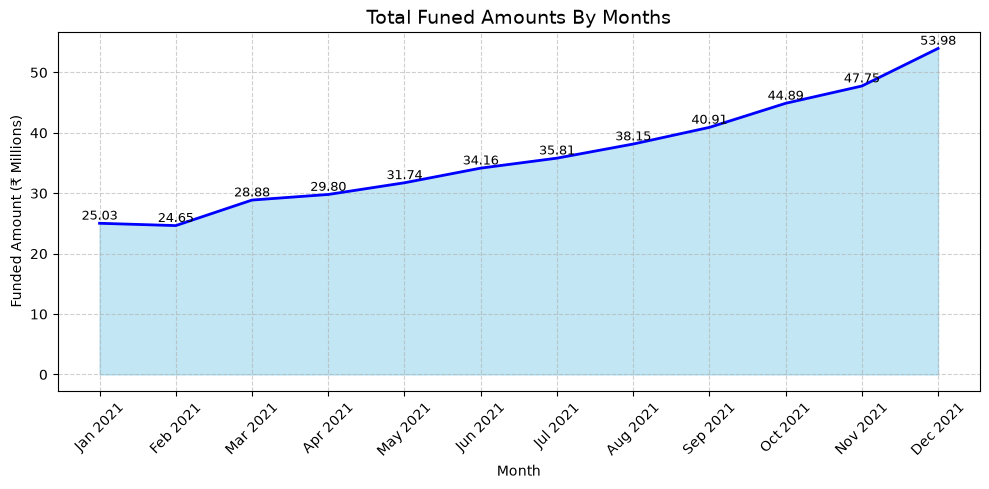

In [63]:
monthly_funded_amount = (
    df.sort_values('issue_date')
    .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
    .groupby('month_name',sort=False)['loan_amount']
    .sum()
    .div(1000_000)
    .reset_index(name = 'loan_amount_millions')
)


plt.figure(figsize=(10,5))
plt.fill_between(monthly_funded_amount['month_name'],monthly_funded_amount['loan_amount_millions'], color='skyblue', alpha=0.5)
plt.plot(monthly_funded_amount['month_name'],monthly_funded_amount['loan_amount_millions'],color:='blue',linewidth=2)

for i, row in monthly_funded_amount.iterrows():
    plt.text(i, row['loan_amount_millions'] + 0.1, f"{row['loan_amount_millions']:.2f}",
             ha='center', va='bottom', fontsize=9, rotation=0,color='black')

plt.title('Total Funed Amounts By Months', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Funded Amount (₹ Millions)')
plt.xticks(ticks=range(len(monthly_funded_amount)), label=monthly_funded_amount['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

### Monthly Trends by Issue Date for Total  Amount Received

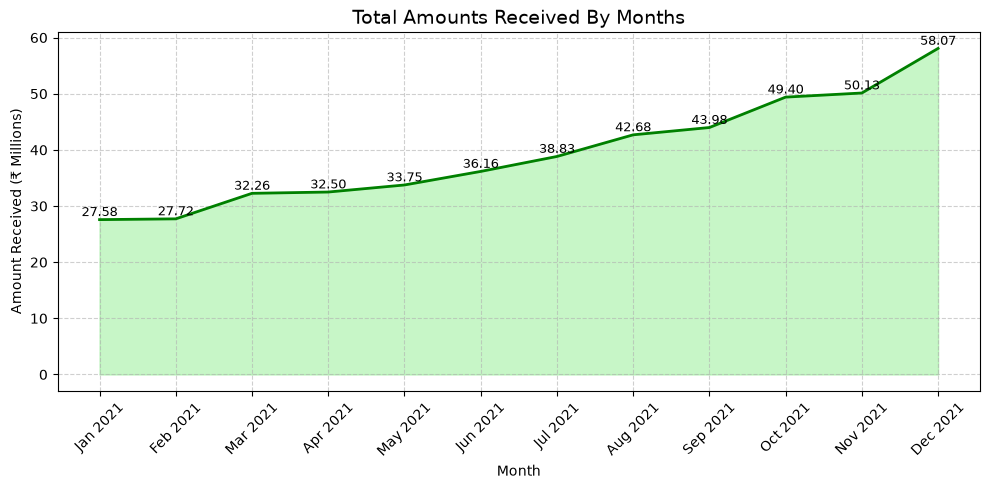

In [64]:
monthly_amount_received = (
    df.sort_values('issue_date')
    .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
    .groupby('month_name',sort=False)['total_payment']
    .sum()
    .div(1000_000)
    .reset_index(name = 'amount_received_millions')
)


plt.figure(figsize=(10,5))
plt.fill_between(monthly_amount_received['month_name'],monthly_amount_received['amount_received_millions'], color='lightgreen', alpha=0.5)
plt.plot(monthly_amount_received['month_name'],monthly_amount_received['amount_received_millions'],color:='green',linewidth=2)

for i, row in monthly_amount_received.iterrows():
    plt.text(i, row['amount_received_millions'] + 0.1, f"{row['amount_received_millions']:.2f}",
             ha='center', va='bottom', fontsize=9, rotation=0,color='black')

plt.title('Total Amounts Received By Months', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Amount Received (₹ Millions)')
plt.xticks(ticks=range(len(monthly_amount_received)), label=monthly_amount_received['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()  

### Monthly Trends by Issue Date for Total  Loan Applications

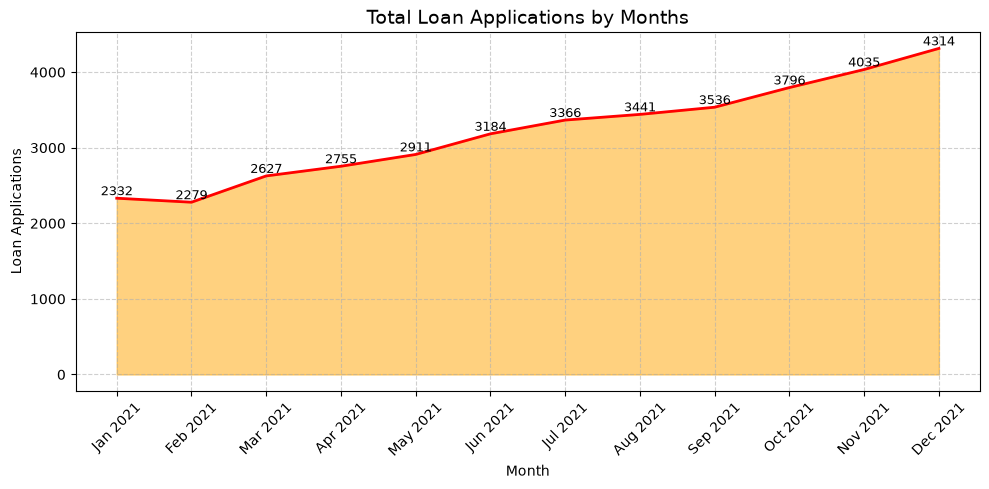

In [107]:
monthly_loan_applications_count = (
    df.sort_values('issue_date')
    .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
    .groupby('month_name',sort=False)['id']
    .count()
    .reset_index(name = 'loan_applications_count')
)


plt.figure(figsize=(10,5))
plt.fill_between(monthly_loan_applications_count['month_name'],monthly_loan_applications_count['loan_applications_count'], color='orange', alpha=0.5)
plt.plot(monthly_loan_applications_count['month_name'],monthly_loan_applications_count['loan_applications_count'],color:='red',linewidth=2)

for i, row in monthly_loan_applications_count.iterrows():
    plt.text(i, row['loan_applications_count'] + 0.1, f"{row['loan_applications_count']}",
             ha='center', va='bottom', fontsize=9, rotation=0,color='black')

plt.title('Total Loan Applications by Months', fontsize=14)
plt.xlabel('Month')
plt.ylabel('Loan Applications')
plt.xticks(ticks=range(len(monthly_loan_applications_count)), label=monthly_loan_applications_count['month_name'], rotation=45)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()  

### Regional Analysis by State for Total Funded Amount

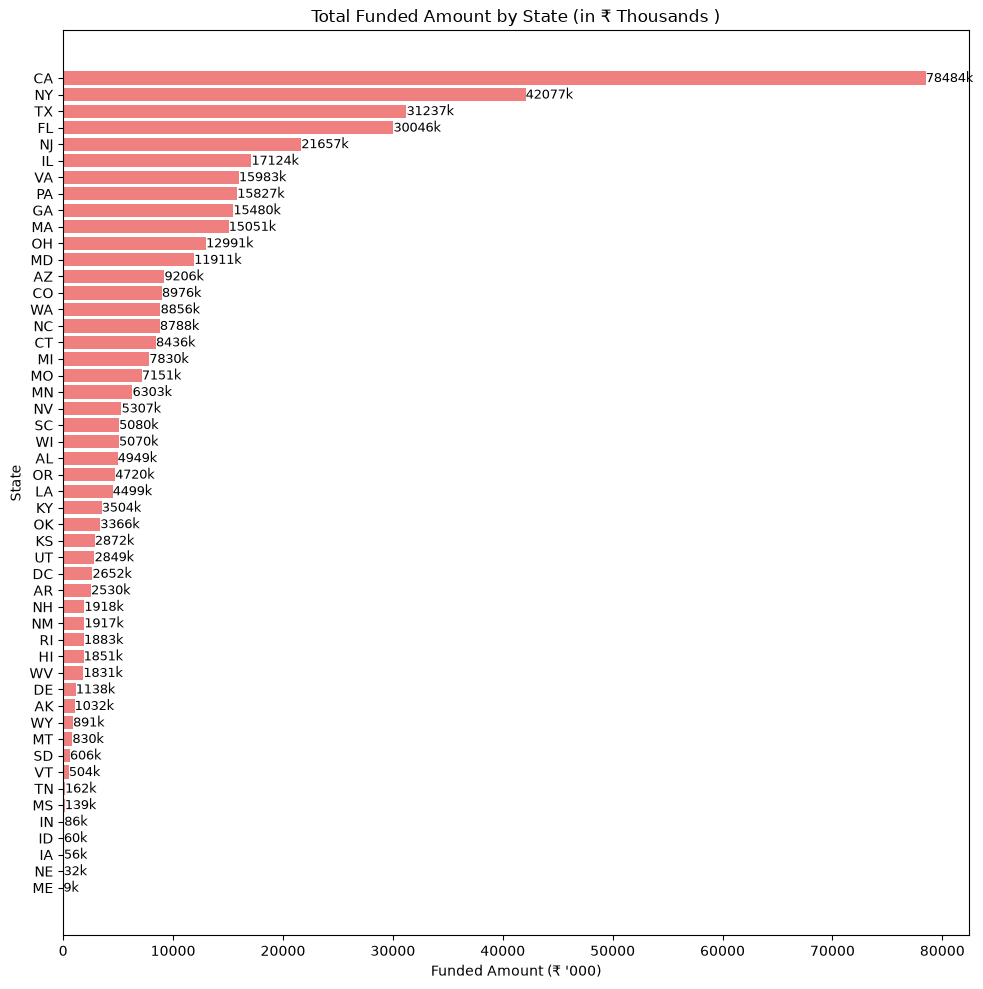

In [71]:
state_funding_amount = df.groupby('address_state')['loan_amount'].sum().sort_values(ascending=True)
state_funding_amount_thousands = state_funding_amount/1000

plt.figure(figsize=(10,10))
bars = plt.barh(state_funding_amount_thousands.index, state_funding_amount_thousands.values,color='lightcoral')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 10,bar.get_y() + bar.get_height()/2,
             f"{width:.0f}k", va='center', fontsize=9)

plt.title('Total Funded Amount by State (in ₹ Thousands )')
plt.xlabel('Funded Amount (₹ \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

### Regional Analysis by State for Total Amount Received

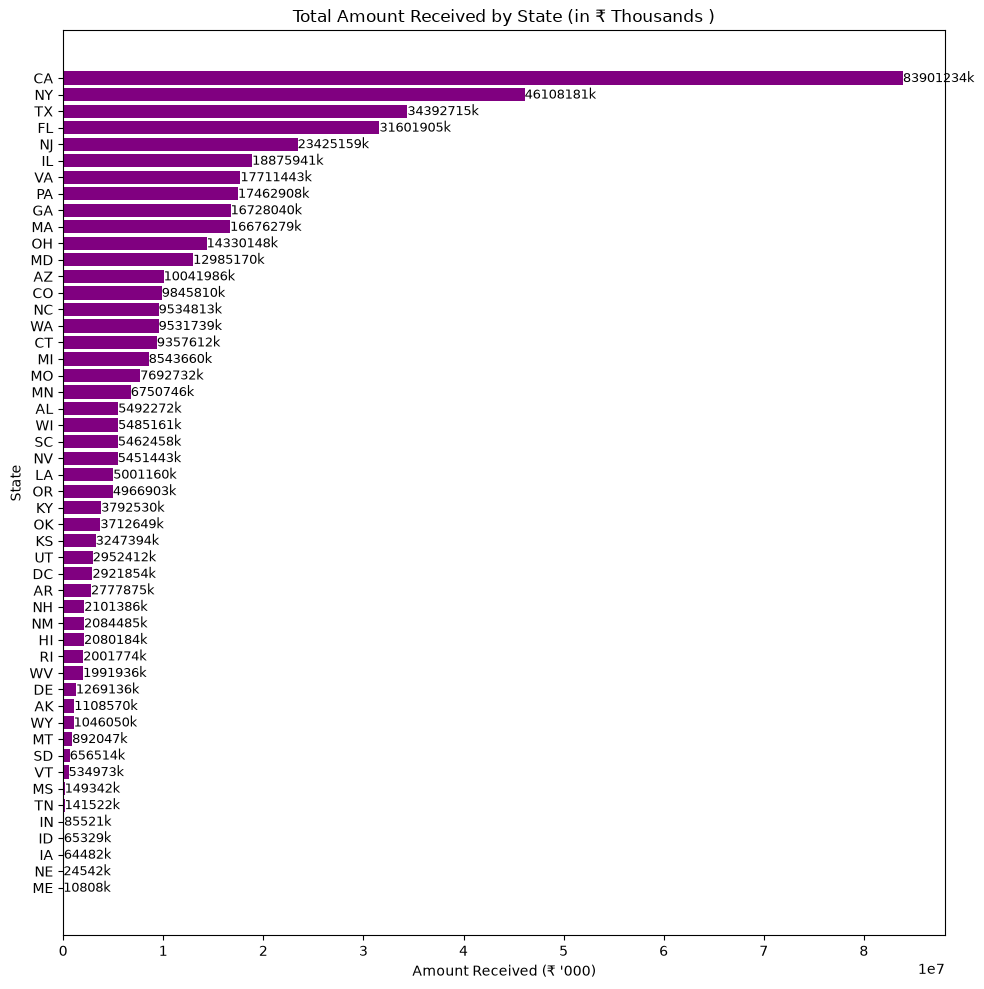

In [75]:
state_amount_received = df.groupby('address_state')['total_payment'].sum().sort_values(ascending=True)
state_amount_received_thousands = state_amount_received

plt.figure(figsize=(10,10))
bars = plt.barh(state_amount_received_thousands.index, state_amount_received_thousands.values,color='purple')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 10,bar.get_y() + bar.get_height()/2,
             f"{width:.0f}k", va='center', fontsize=9)

plt.title('Total Amount Received by State (in ₹ Thousands )')
plt.xlabel('Amount Received (₹ \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

### Regional Analysis by State for Total Loan Applications

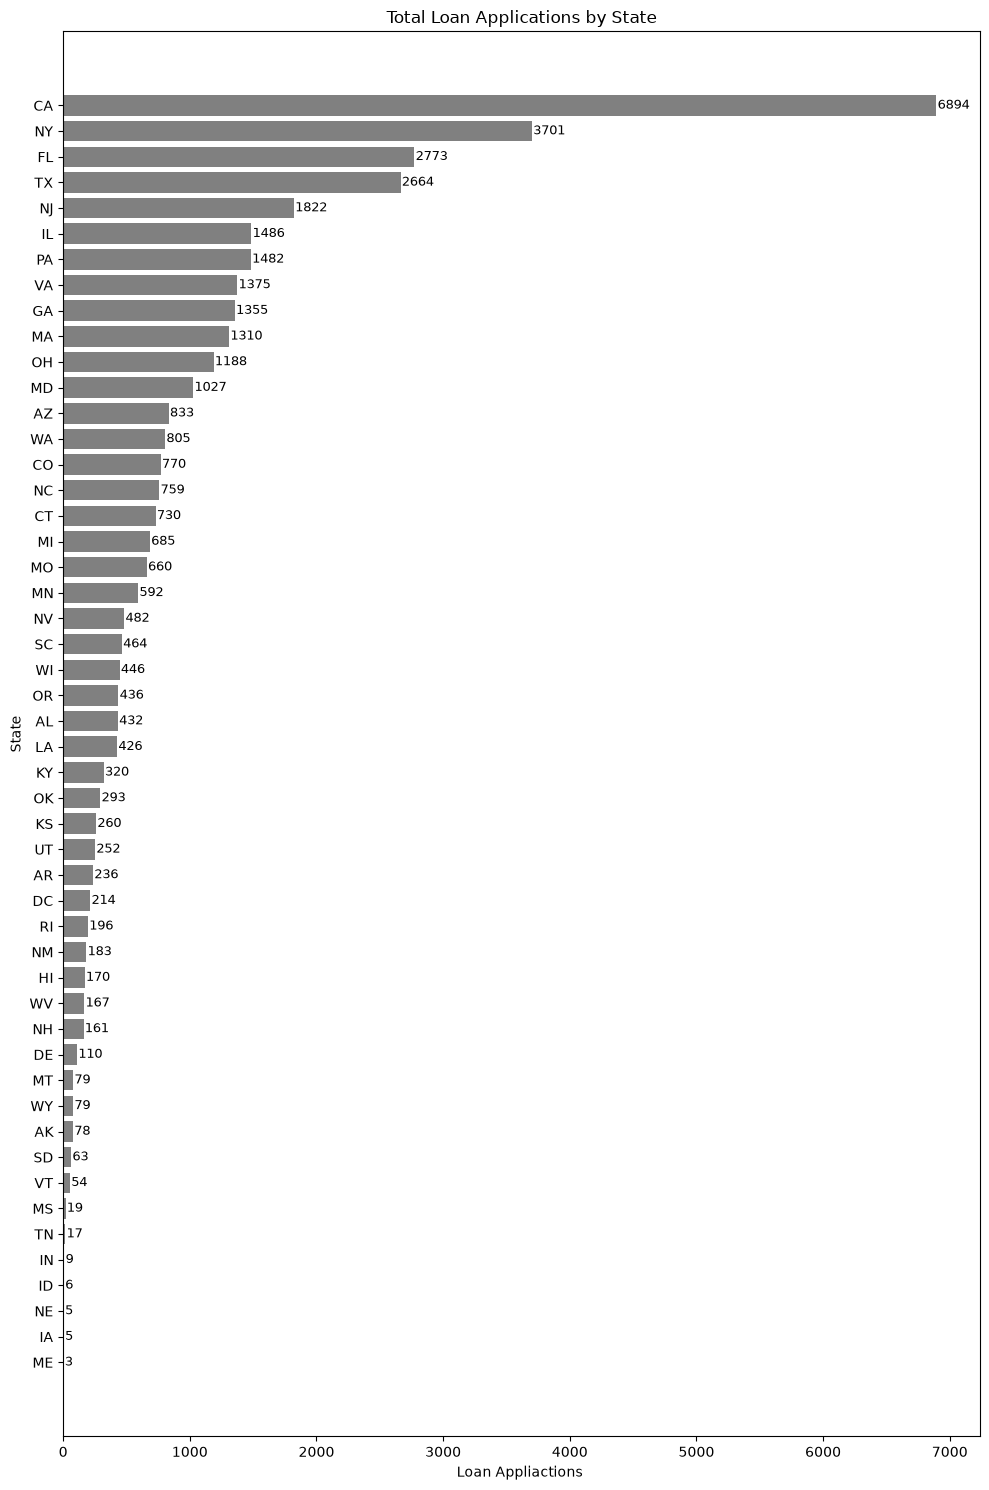

In [85]:
state_loan_applications = df.groupby('address_state')['id'].count().sort_values(ascending=True)
state_loan_applications_thousands = state_loan_applications

plt.figure(figsize=(10,15))
bars = plt.barh(state_loan_applications_thousands.index, state_loan_applications_thousands.values,color='grey')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 10,bar.get_y() + bar.get_height()/2,
             f"{width}", va='center', fontsize=9)

plt.title('Total Loan Applications by State')
plt.xlabel('Loan Appliactions ')
plt.ylabel('State')
plt.tight_layout()
plt.show()

### Loan Term Analysis by Total Funded Amount

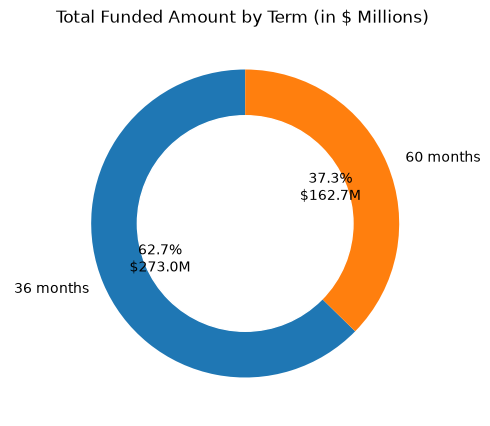

In [92]:
term_funded_amount_millions = df.groupby('term')['loan_amount'].sum()/1000000

plt.figure(figsize=(5,5))
plt.pie(
    term_funded_amount_millions,
    labels = term_funded_amount_millions.index,
    autopct =lambda p: f"{p:.1f}%\n${p*sum(term_funded_amount_millions)/100:.1f}M",
    startangle=90,
    wedgeprops={'width': 0.4}
)
plt.gca().add_artist(plt.Circle((0,0),0.70, color='white'))
plt.title("Total Funded Amount by Term (in $ Millions) ")
plt.show()

### Loan Term Analysis by Total Amount Received

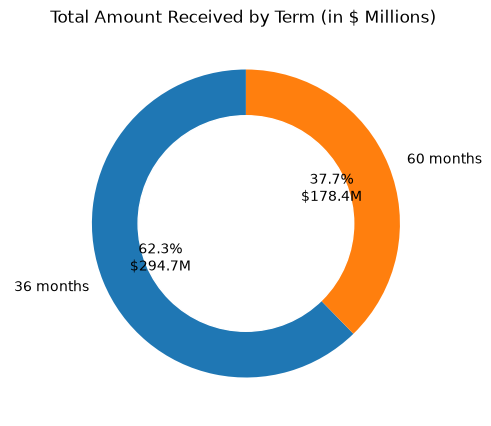

In [95]:
term_amount_received_millions = df.groupby('term')['total_payment'].sum()/1000000

plt.figure(figsize=(5,5))
plt.pie(
    term_amount_received_millions,
    labels = term_amount_received_millions.index,
    autopct =lambda p: f"{p:.1f}%\n${p*sum(term_amount_received_millions)/100:.1f}M",
    startangle=90,
    wedgeprops={'width': 0.4}
)
plt.gca().add_artist(plt.Circle((0,0),0.7, color='white'))
plt.title("Total Amount Received by Term (in $ Millions) ")
plt.show()

### Loan Term Analysis by Total Loan Applications

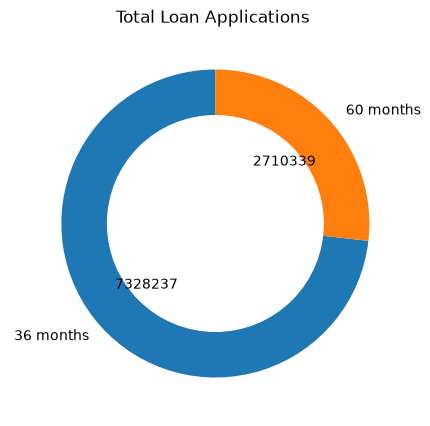

In [100]:
term_loan_applications = df.groupby('term')['id'].count()

plt.figure(figsize=(5,5))
plt.pie(
    term_loan_applications,
    labels = term_loan_applications.index,
    autopct =lambda p: f"{p:.0f}{p*sum(term_loan_applications)/100:.0f}",
    startangle=90,
    wedgeprops={'width': 0.4}
)
plt.gca().add_artist(plt.Circle((0,0),0.7, color='white'))
plt.title("Total Loan Applications ")
plt.show()

### Employee Length by Total Funded Amount

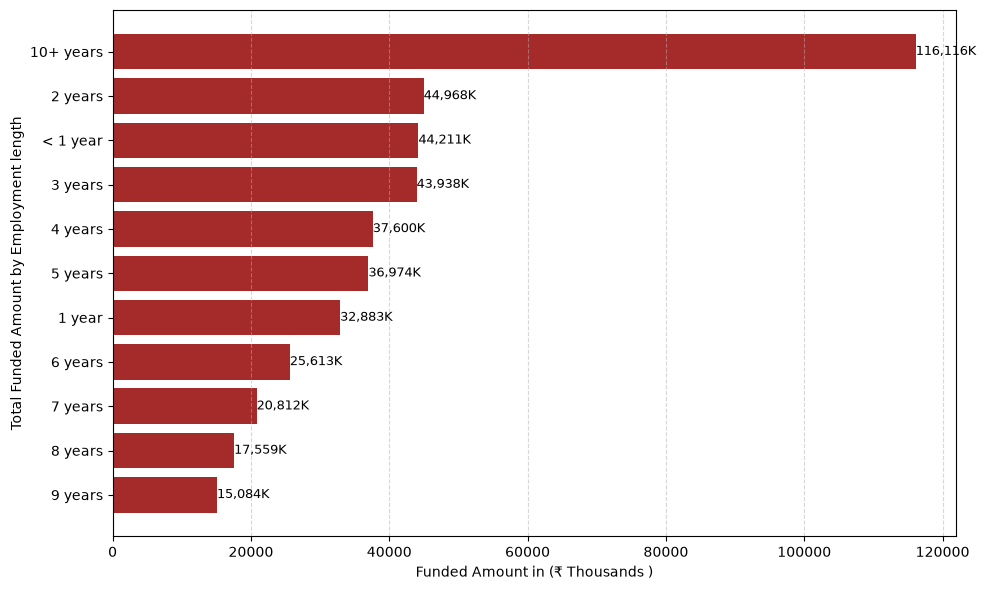

In [102]:
emp_funded_amount_in_thousands = df.groupby('emp_length')['loan_amount'].sum().sort_values()/1000

plt.figure(figsize=(10,6))
bars = plt.barh(emp_funded_amount_in_thousands.index, emp_funded_amount_in_thousands, color='brown')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() /2,
            f"{width:,.0f}K",va = 'center', fontsize=9)

plt.xlabel("Funded Amount in (₹ Thousands )")
plt.ylabel("Total Funded Amount by Employment length")
plt.grid(axis ='x',linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Employee Length by Total Amount Received

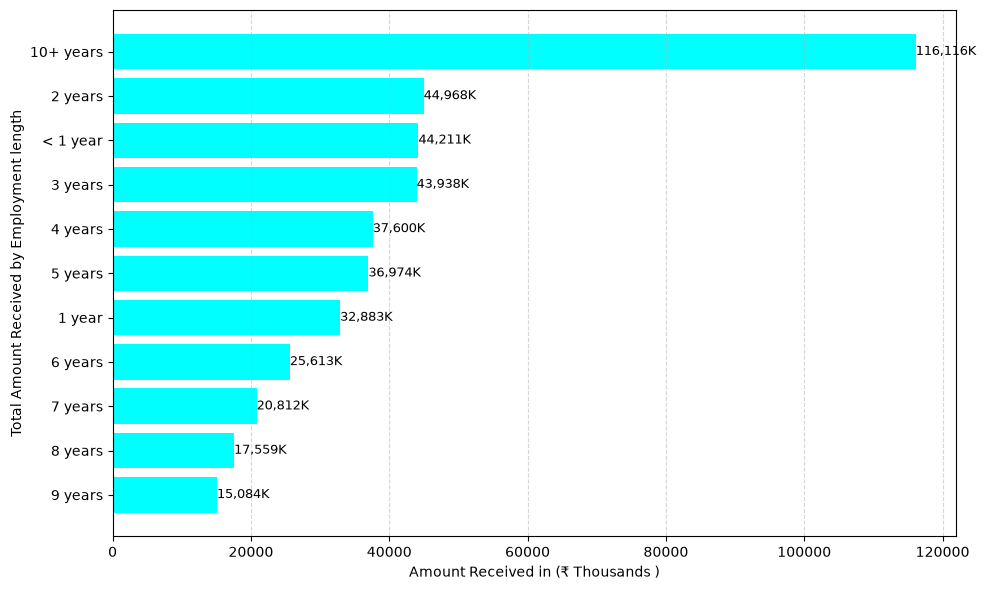

In [103]:
emp_amount_received_in_thousands = df.groupby('emp_length')['loan_amount'].sum().sort_values()/1000

plt.figure(figsize=(10,6))
bars = plt.barh(emp_amount_received_in_thousands.index, emp_amount_received_in_thousands, color='cyan')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() /2,
            f"{width:,.0f}K",va = 'center', fontsize=9)

plt.xlabel("Amount Received in (₹ Thousands )")
plt.ylabel("Total Amount Received by Employment length")
plt.grid(axis ='x',linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Employee Length by Total Loan Applications

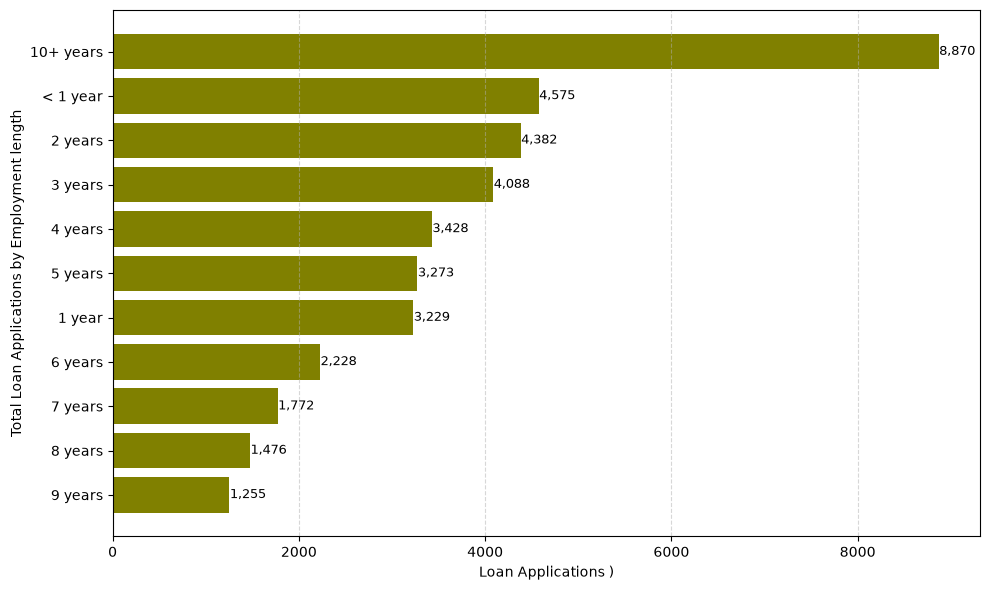

In [109]:
emp_loan_applications = df.groupby('emp_length')['loan_amount'].count().sort_values()

plt.figure(figsize=(10,6))
bars = plt.barh(emp_loan_applications.index, emp_loan_applications, color='olive')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() /2,
            f"{width:,.0f}",va = 'center', fontsize=9)

plt.xlabel("Loan Applications )")
plt.ylabel("Total Loan Applications by Employment length")
plt.grid(axis ='x',linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Loan Purpose Breakdown by Total Funded Amount

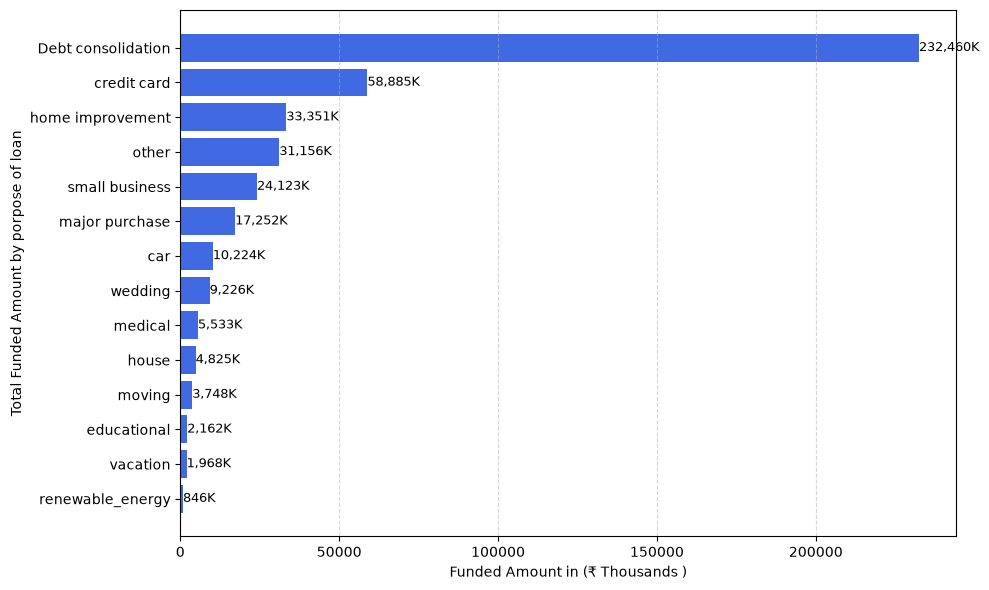

In [111]:
purpose_funded_amount_thousands = df.groupby('purpose')['loan_amount'].sum().sort_values()/1000

plt.figure(figsize=(10,6))
bars = plt.barh(purpose_funded_amount_thousands.index, purpose_funded_amount_thousands, color='royalblue')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() /2,
            f"{width:,.0f}K",va = 'center', fontsize=9)

plt.xlabel("Funded Amount in (₹ Thousands )")
plt.ylabel("Total Funded Amount by porpose of loan")
plt.grid(axis ='x',linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Loan Purpose Breakdown by Total Amount Received

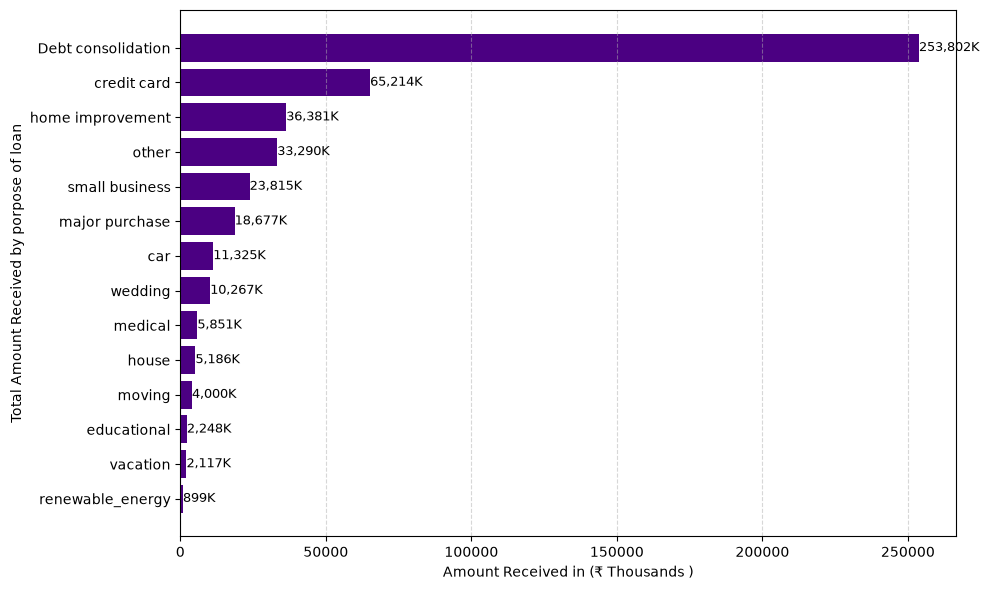

In [118]:
purpose_amount_received_thousands = df.groupby('purpose')['total_payment'].sum().sort_values()/1000

plt.figure(figsize=(10,6))
bars = plt.barh(purpose_amount_received_thousands.index, purpose_amount_received_thousands, color='indigo')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() /2,
            f"{width:,.0f}K",va = 'center', fontsize=9)

plt.xlabel("Amount Received in (₹ Thousands )")
plt.ylabel("Total Amount Received by porpose of loan")
plt.grid(axis ='x',linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Loan Purpose Breakdown by Total Loan Applications

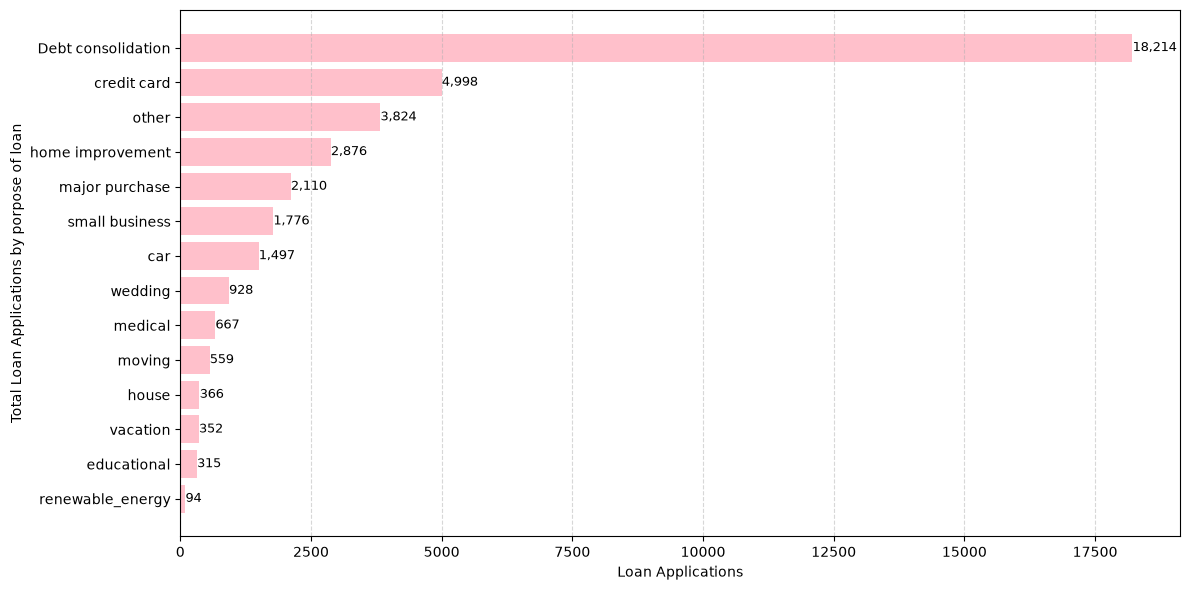

In [124]:
purpose_of_loan_applications = df.groupby('purpose')['id'].count().sort_values()

plt.figure(figsize=(12,6))
bars = plt.barh(purpose_of_loan_applications.index, purpose_of_loan_applications, color='pink')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height() /2,
            f"{width:,.0f}",va = 'center', fontsize=9)

plt.xlabel("Loan Applications")
plt.ylabel("Total Loan Applications by porpose of loan")
plt.grid(axis ='x',linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### Home ownership by Total Funded Amount

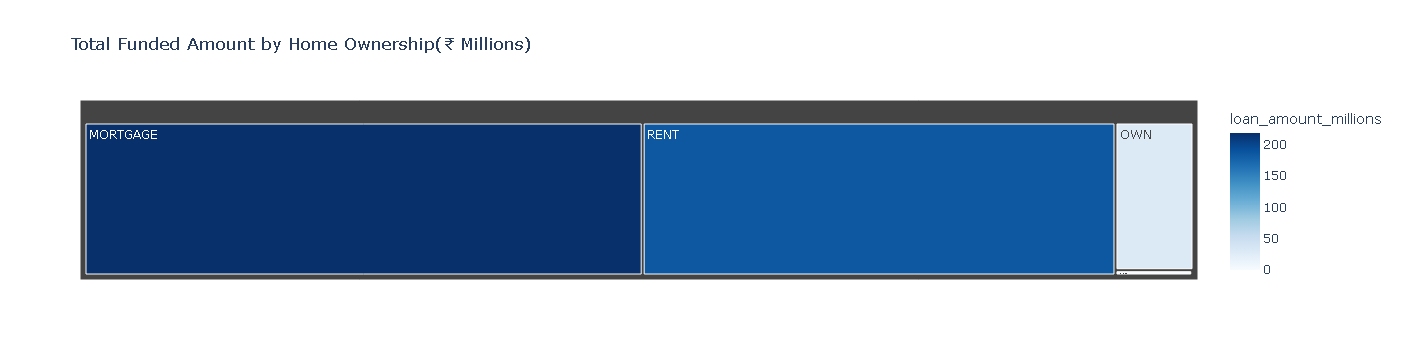

In [130]:
home_funding_amount = df.groupby('home_ownership')['loan_amount'].sum().reset_index()
home_funding_amount['loan_amount_millions'] = home_funding_amount['loan_amount']/1000000

fig = px.treemap(
    home_funding_amount,
    path=['home_ownership'],
    values='loan_amount_millions',
    color='loan_amount_millions',
    color_continuous_scale='Blues',
    title='Total Funded Amount by Home Ownership(₹ Millions)'
)

fig.show()

### Home ownership by Total Amount Received

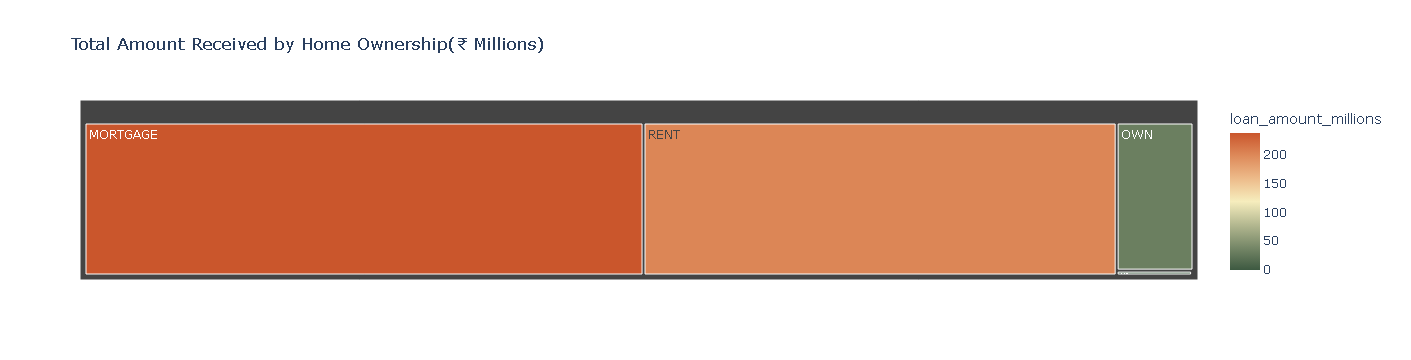

In [136]:
home_amount_received = df.groupby('home_ownership')['total_payment'].sum().reset_index()
home_amount_received['loan_amount_millions'] = home_amount_received['total_payment']/1000000

fig = px.treemap(
    home_amount_received,
    path=['home_ownership'],
    values='loan_amount_millions',
    color='loan_amount_millions',
    color_continuous_scale='fall',
    title='Total Amount Received by Home Ownership(₹ Millions)'
)

fig.show()

### Home ownership by Total Loan Applications

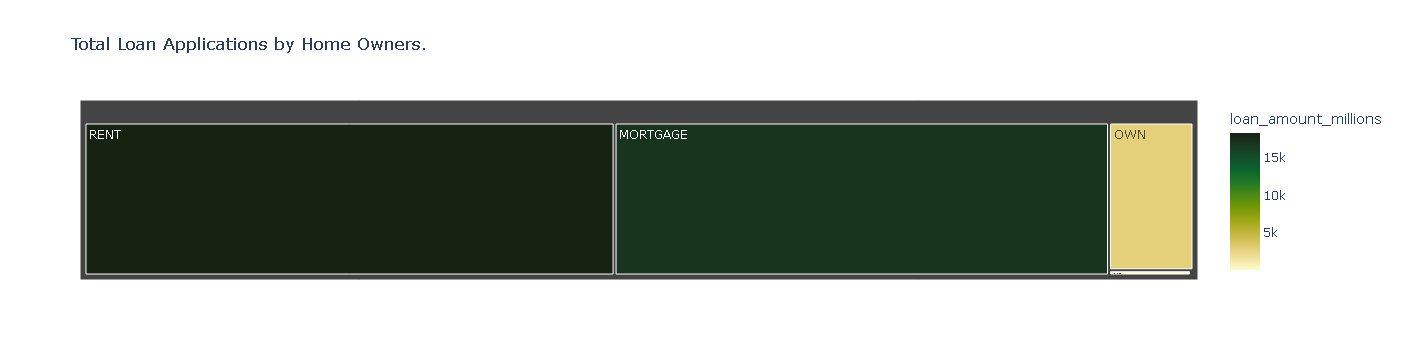

In [139]:
home_loan_applications = df.groupby('home_ownership')['id'].count().reset_index()
home_loan_applications['loan_amount_millions'] = home_loan_applications['id']

fig = px.treemap(
    home_loan_applications,
    path=['home_ownership'],
    values='loan_amount_millions',
    color='loan_amount_millions',
    color_continuous_scale='speed',
    title='Total Loan Applications by Home Owners.'
)

fig.show()